In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv("/content/sales_data_sample.csv",encoding="latin")

In [ ]:
print(df.head())
print(df.shape)
print(df.info())
print(df.columns)

   ORDERNUMBER  QUANTITYORDERED  ...  CONTACTFIRSTNAME  DEALSIZE
0        10107               30  ...              Kwai     Small
1        10121               34  ...              Paul     Small
2        10134               41  ...            Daniel    Medium
3        10145               45  ...             Julie    Medium
4        10159               49  ...             Julie    Medium

[5 rows x 25 columns]
(2823, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  

In [ ]:
features = ["QUANTITYORDERED","PRICEEACH","SALES","MSRP"]

In [ ]:

X = df[features].apply(
    pd.to_numeric,
    errors='coerce'
)

In [ ]:
X = X.dropna()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
wcss = []
for k in range(1,11):
  kmeans = KMeans (
      n_clusters = k,
      init = 'k-means++',
      random_state = 42,
      n_init = 10

  )

  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)



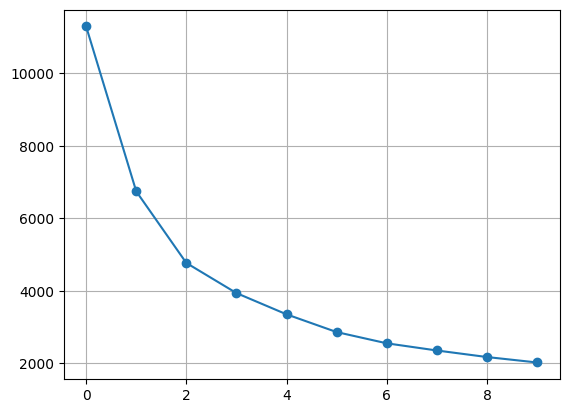

In [ ]:
plt.plot(wcss,marker="o")
plt.grid()

In [ ]:
optimal_k = 3
kmeans = KMeans(
    n_clusters = optimal_k,
    random_state = 42,
    init = 'k-means++'

)

clusters = kmeans.fit_predict(X_scaled)

In [ ]:
result = X.copy()
result['Clusters'] = clusters

In [ ]:
print("\nCluster Assignments:")
print(result.head(10))


Cluster Assignments:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  Clusters
0               30      95.70  2871.00    95         0
1               34      81.35  2765.90    95         0
2               41      94.74  3884.34    95         2
3               45      83.26  3746.70    95         2
4               49     100.00  5205.27    95         2
5               36      96.66  3479.76    95         0
6               29      86.13  2497.77    95         0
7               48     100.00  5512.32    95         2
8               22      98.57  2168.54    95         0
9               41     100.00  4708.44    95         2


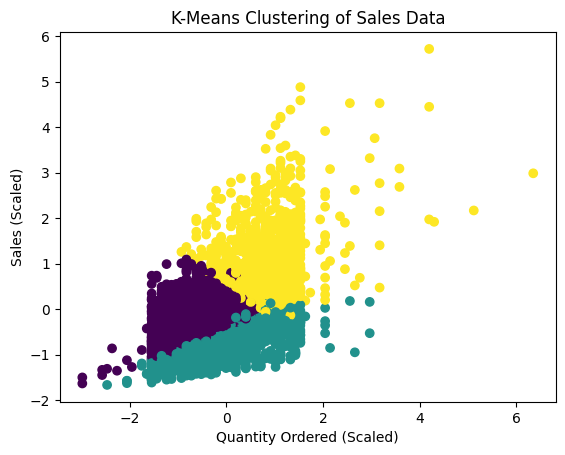

In [ ]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=clusters
)

plt.title('K-Means Clustering of Sales Data')
plt.xlabel('Quantity Ordered (Scaled)')
plt.ylabel('Sales (Scaled)')

plt.show()

In [ ]:
print("\nCluster Centers:")

print(pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features
))


Cluster Centers:
   QUANTITYORDERED  PRICEEACH        SALES        MSRP
0        27.623246  95.432565  3124.445842  113.206413
1        35.208205  59.551169  2101.076482   64.145641
2        43.730588  97.487035  5724.567447  127.997647
